# Class 2 - Arrays, loops and objects

Run the cells from top to bottom. Predict each result before running it, then change the suggested inputs. Uses basic Python 3 syntax and NumPy. Install a NumPy version compatible with your Python environment.

Code is deliberately more complete here than in the slides. No assertions or advanced print formatting are used. `print("Label:", value)` prints a label and value separated by a space.

The small diagrams are copied from the lecture for reference. They illustrate the original inputs; change the code to explore other cases.


## 1. Running and importing
A function can be reused without automatically running its example checks. When a file is run directly, its `__name__` is `"__main__"`; when it is imported, `__name__` is the module name.

The next cell is the content of a small Python file. In a notebook, the main block also runs because the notebook's top-level name is `"__main__"`.


In [1]:
def square(x):
    """Return the square of x."""
    return x * x

if __name__ == "__main__":
    print("square(0):", square(0), "expected:", 0)
    print("square(-3):", square(-3), "expected:", 9)


square(0): 0 expected: 0
square(-3): 9 expected: 9


### Try the two-file version
This helper cell saves the same example into `class-02-files/squares_demo.py`. File creation is just setup for the demonstration; it is not something you need to memorise here.


In [2]:
import os
import sys
import subprocess

folder = "class-02-files"
if not os.path.isdir(folder):
    os.makedirs(folder)
source = '''def square(x):
    return x * x

if __name__ == "__main__":
    print("Direct run:", square(-3), "expected:", 9)
'''
with open(os.path.join(folder, "squares_demo.py"), "w") as file:
    file.write(source)

process = subprocess.Popen(
    [sys.executable, "squares_demo.py"], cwd=folder,
    stdout=subprocess.PIPE, universal_newlines=True)
output, unused = process.communicate()
print(output, end="")


Direct run: 9 expected: 9


Importing the module below does not print the `Direct run` line. The function is still available to call. The temporary search-path entry tells Python where the demonstration file was saved.


In [3]:
sys.path.insert(0, os.path.abspath(folder))
import squares_demo
sys.path.pop(0)
print("Import complete: no main-block output above.")
print("Explicit function call:", squares_demo.square(5), "expected:", 25)


Import complete: no main-block output above.
Explicit function call: 25 expected: 25


## 2. NumPy arrays
### Temperature measurements
Rows are days; columns are morning, midday, afternoon and evening. Values are in degrees Celsius. Indices begin at zero.

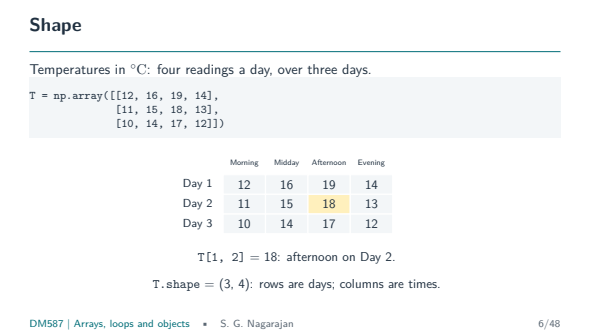


In [4]:
import numpy as np
T = np.array([[12, 16, 19, 14],
              [11, 15, 18, 13],
              [10, 14, 17, 12]])
print(T)
print("Shape:", T.shape)
print("Day 2 afternoon:", T[1, 2], "expected:", 18)


[[12 16 19 14]
 [11 15 18 13]
 [10 14 17 12]]
Shape: (3, 4)
Day 2 afternoon: 18 expected: 18


### Slicing
Select midday and afternoon on the first two days. Start indices are included; stop indices are excluded.

A basic slice is a view: changing it changes T. Use `T[:2, 1:3].copy()` to obtain independent data.

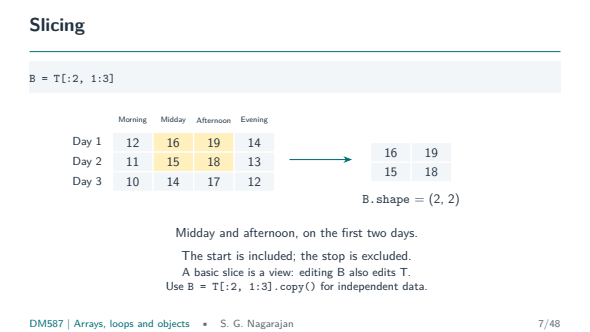


In [5]:
B = T[:2, 1:3]
print(B)
print("Shape:", B.shape, "expected:", (2, 2))


[[16 19]
 [15 18]]
Shape: (2, 2) expected: (2, 2)


### Dimensions
An integer selects one row as a 1D array; a slice keeps the result as a 2D table. Compare T[1, :] with T[1:2, :]: the readings are the same, but the shapes are (4,) and (1, 4). A 1D array is neither a row nor a column.

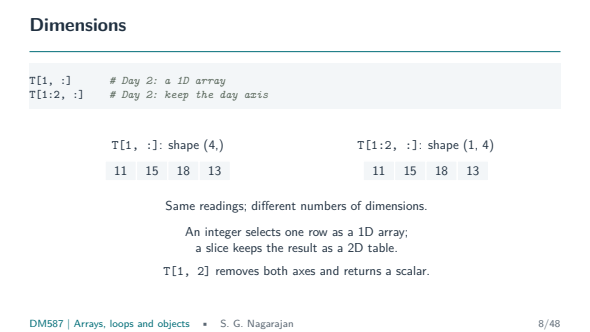


In [6]:
print("One day, 1D:", T[1, :], "shape:", T[1, :].shape)
print("One day, 2D:", T[1:2, :], "shape:", T[1:2, :].shape)


One day, 1D: [11 15 18 13] shape: (4,)
One day, 2D: [[11 15 18 13]] shape: (1, 4)


### Retrieval quiz
Before running the answers, write slices for:
1. Afternoon on all days.
2. All readings on the last two days.
3. Morning and afternoon on the first two days.

Predict values and shapes.

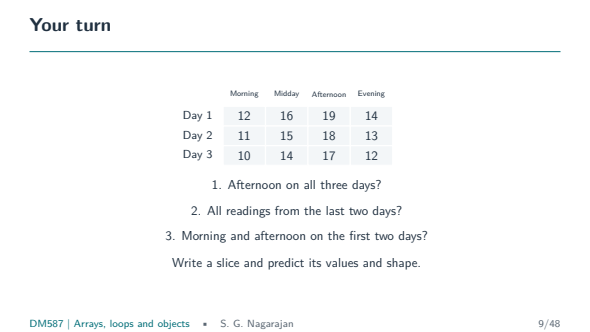


In [7]:
print("1. Afternoon:", T[:, 2], "shape:", T[:, 2].shape)
print("2. Last two days:")
print(T[1:, :])
print("Shape:", T[1:, :].shape)
print("3. Morning and afternoon:")
print(T[:2, ::2])
print("Shape:", T[:2, ::2].shape)

print("Alternative, explicit column indices:")
print(T[:2, [0, 2]])


1. Afternoon: [19 18 17] shape: (3,)
2. Last two days:
[[11 15 18 13]
 [10 14 17 12]]
Shape: (2, 4)
3. Morning and afternoon:
[[12 19]
 [11 18]]
Shape: (2, 2)
Alternative, explicit column indices:
[[12 19]
 [11 18]]


An alternative to `T[:2, ::2]` is `T[:2, [0, 2]]`: a row slice together with an explicit list of column indices. Both give the same values here. A list can select arbitrary columns or change their order, for example `T[:2, [3, 0]]`. List-based (advanced) indexing returns a copy; basic slicing gives a view.


### Reshaping
A device exports one flat sequence. To reconstruct our three-day, four-time table, match the reshape order to how the readings were saved. Day-by-day storage groups four readings per day: use C order. Time-by-time storage groups the three mornings, then the three middays, and so on: use F order. The two input sequences differ, but the correctly reconstructed tables are identical.

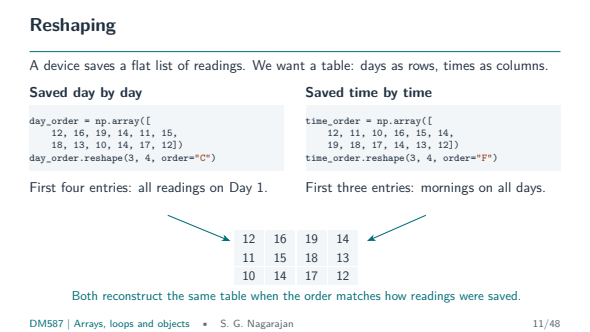


In [8]:
data = np.array([12, 16, 19, 14, 11, 15, 18, 13, 10, 14, 17, 12])
print("Day-by-day input, C order:")
print(data.reshape(3, 4, order="C"))
print("Same input, F order:")
print(data.reshape(3, 4, order="F"))
time_grouped = np.array([12, 11, 10, 16, 15, 14, 19, 18, 17, 14, 13, 12])
print("All mornings, then middays, afternoons, evenings: use F order")
print(time_grouped.reshape(3, 4, order="F"))
print("Infer the number of days:", data.reshape(-1, 4).shape)


Day-by-day input, C order:
[[12 16 19 14]
 [11 15 18 13]
 [10 14 17 12]]
Same input, F order:
[[12 14 18 14]
 [16 11 13 17]
 [19 15 10 12]]
All mornings, then middays, afternoons, evenings: use F order
[[12 16 19 14]
 [11 15 18 13]
 [10 14 17 12]]
Infer the number of days: (3, 4)


### Views and copies
Editing a basic slice edits the original readings. Use a fresh copy of T here so later examples retain the original values. A reshape may share data or require a copy, depending on the layout.


In [9]:
original = T.copy()
view = original[:2, 1:3]
independent = view.copy()
view[0, 0] = 17
print("Original after editing the view:")
print(original)
print("Independent copy still has the old reading:")
print(independent)


Original after editing the view:
[[12 17 19 14]
 [11 15 18 13]
 [10 14 17 12]]
Independent copy still has the old reading:
[[16 19]
 [15 18]]


### Stacking
Add a row for a new day or a column for night-time readings. For vstack, column counts must agree; for hstack, row counts must agree. These examples use 2D inputs.

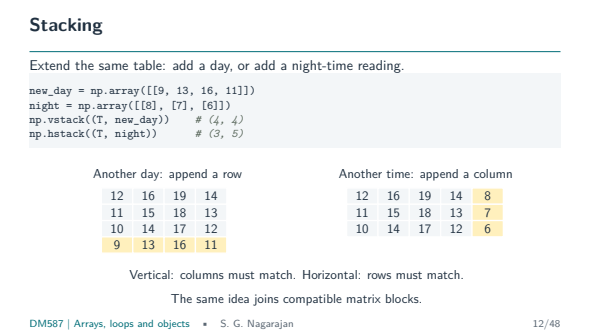


In [10]:
new_day = np.array([[9, 13, 16, 11]])
night = np.array([[8], [7], [6]])
vertical = np.vstack((T, new_day))
horizontal = np.hstack((T, night))
print("Another day:")
print(vertical)
print("Shape:", vertical.shape)
print("Another measurement time:")
print(horizontal)
print("Shape:", horizontal.shape)


Another day:
[[12 16 19 14]
 [11 15 18 13]
 [10 14 17 12]
 [ 9 13 16 11]]
Shape: (4, 4)
Another measurement time:
[[12 16 19 14  8]
 [11 15 18 13  7]
 [10 14 17 12  6]]
Shape: (3, 5)


### Predict the shape: hstack
Compare 1D inputs of shape (2,) with 2D column inputs of shape (2, 1). Predict values and shapes before executing.

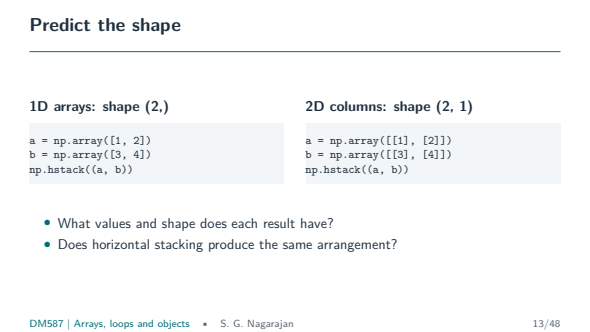


In [11]:
a = np.array([1, 2])
b = np.array([3, 4])
joined_1d = np.hstack((a, b))
print("1D inputs:", joined_1d, "shape:", joined_1d.shape)
a = np.array([[1], [2]])
b = np.array([[3], [4]])
joined_2d = np.hstack((a, b))
print("2D column inputs:")
print(joined_2d)
print("Shape:", joined_2d.shape)


1D inputs: [1 2 3 4] shape: (4,)
2D column inputs:
[[1 3]
 [2 4]]
Shape: (2, 2)


For 1D inputs, hstack joins along the only axis, producing [1, 2, 3, 4] with shape (4,). For 2D inputs it joins columns, producing [[1, 3], [2, 4]] with shape (2, 2). A length-two vector and a two-row column have different numbers of dimensions.


### Axes and broadcasting
`T.mean(axis=0)` averages the three days at each time, giving four values (one per column). `T.mean(axis=1)` averages the four times for each day, giving three values (one per row). A length-4 correction is applied to all rows.

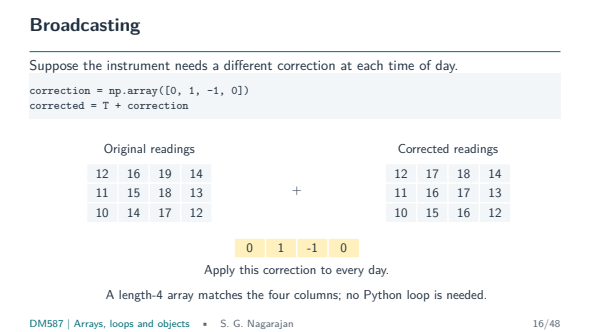


In [12]:
print("Mean at each time:", T.mean(axis=0))
print("Mean for each day:", T.mean(axis=1))
correction = np.array([0, 1, -1, 0])
print("Corrected readings:")
print(T + correction)


Mean at each time: [11. 15. 18. 13.]
Mean for each day: [15.25 14.25 13.25]
Corrected readings:
[[12 17 18 14]
 [11 16 17 13]
 [10 15 16 12]]


### Optional: selecting warm readings
Boolean indexing selects entries that satisfy a condition and produces a copy. This is different from a basic slice.


In [13]:
print("Readings above 16 degrees:", T[T > 16])


Readings above 16 degrees: [19 18 17]


## 3. Loops and comprehensions
### Loop basics
A for loop visits values directly. range supplies integer steps; enumerate supplies index-value pairs. np.arange creates a NumPy array and accepts a numerical step. Both range and arange exclude the stop (floating-point rounding can affect non-exact steps in arange).

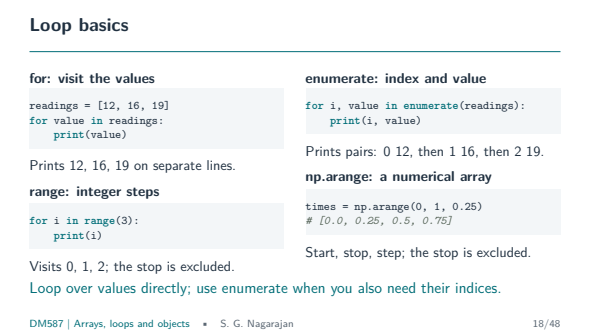


In [14]:
readings = [12, 16, 19]
print("Values:")
for value in readings:
    print(value)
print("range(3):")
for i in range(3):
    print(i)
print("Index and value:")
for i, value in enumerate(readings):
    print(i, value)
times = np.arange(0, 1, 0.25)
print("Numerical sampling times:", times)


Values:
12
16
19
range(3):
0
1
2
Index and value:
0 12
1 16
2 19
Numerical sampling times: [0.   0.25 0.5  0.75]


### Transforming a list
A loop can build a new list step by step. A comprehension expresses the same transformation in one line.

**Change it:** build cubes rather than squares. Then use a list containing negative numbers.

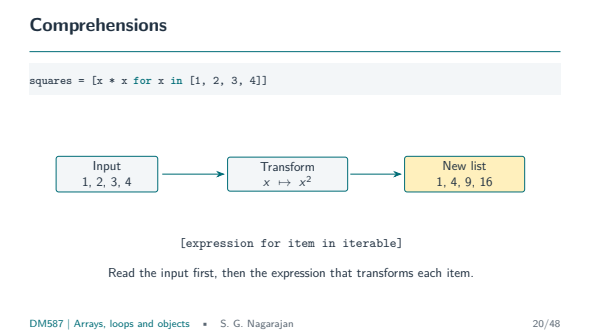


In [15]:
values = [1, 2, 3, 4]
squares_loop = []
for x in values:
    squares_loop.append(x * x)
squares = [x * x for x in values]
print("Loop:", squares_loop)
print("Comprehension:", squares)
print("Same values:", squares_loop == squares)


Loop: [1, 4, 9, 16]
Comprehension: [1, 4, 9, 16]
Same values: True


### Filtering
The trailing `if` decides whether an item is included. The expression at the front transforms each included item.

**Change it:** keep even numbers instead; then select numbers greater than 2.

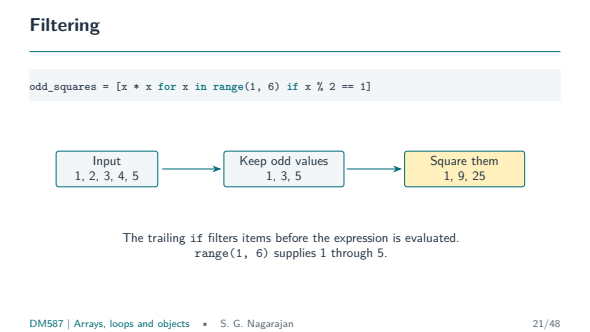


In [16]:
odd_squares = [x * x for x in range(1, 6) if x % 2 == 1]
print("Odd squares:", odd_squares, "expected:", [1, 9, 25])


Odd squares: [1, 9, 25] expected: [1, 9, 25]


### Filtering quiz
Use values = [-2, -1, 0, 1, 2, 3]. Predict the three results before running the next cell. Compare two conditions, filtering then squaring, and replacing values while keeping all input positions.

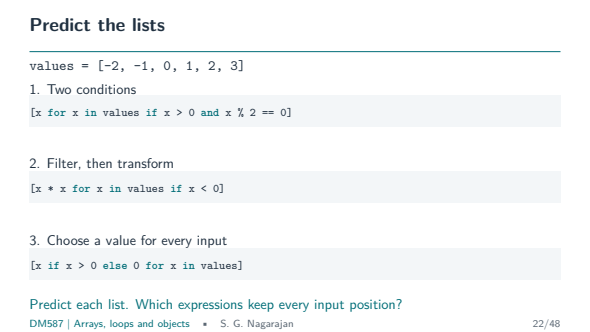


In [17]:
values = [-2, -1, 0, 1, 2, 3]
print("1. Positive and even:", [x for x in values if x > 0 and x % 2 == 0])
print("2. Squares of negatives:", [x * x for x in values if x < 0])
print("3. Replace non-positive values:", [x if x > 0 else 0 for x in values])


1. Positive and even: [2]
2. Squares of negatives: [4, 1]
3. Replace non-positive values: [0, 0, 0, 1, 2, 3]


The answers are [2], [4, 1], and [0, 0, 0, 1, 2, 3]. A trailing if filters inputs; an if/else expression before for chooses an output for every input, preserving the number of items.


### Nested iteration
This creates a single list of six tuples, not a matrix. The first for is the outer loop: append all three pairs with i=1, then all three with i=2.

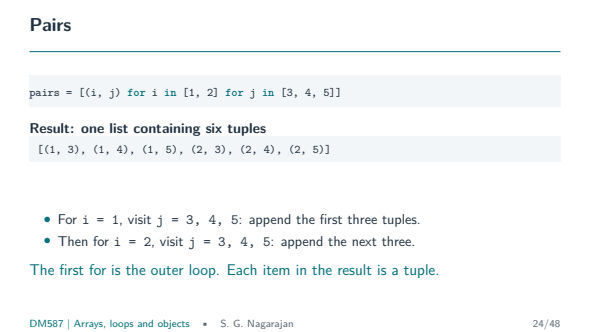


In [18]:
pairs = [(i, j) for i in [1, 2] for j in [3, 4, 5]]
print(pairs)
print("Number of pairs:", len(pairs), "expected:", 6)


[(1, 3), (1, 4), (1, 5), (2, 3), (2, 4), (2, 5)]
Number of pairs: 6 expected: 6


### zip and enumerate
Names and ages are separate lists. Their matching positions describe the same person. zip pairs corresponding entries; it does not form all combinations, and it stops at the shorter list. enumerate supplies an index and a value.

Try removing an age and observe which person is omitted.


In [19]:
names = ["Ada", "Emmy", "Sofia"]
ages = [20, 22, 21]
for name, age in zip(names, ages):
    print(name, age)
print("Names with indices:")
for i, name in enumerate(names):
    print(i, name)


Ada 20
Emmy 22
Sofia 21
Names with indices:
0 Ada
1 Emmy
2 Sofia


### Optional: while loops
This iteration repeatedly halves the distance to the target. A tolerance gives a practical stopping rule. A step limit prevents an endless calculation if the update is changed incorrectly.

**Change it:** reduce the tolerance and compare the number of steps.


In [20]:
x = 0.0
target = 1.0
tolerance = 0.01
steps = 0
while abs(x - target) > tolerance and steps < 100:
    x = (x + target) / 2
    steps += 1
print("Approximation:", x)
print("Absolute error:", abs(x - target))
print("Steps:", steps)


Approximation: 0.9921875
Absolute error: 0.0078125
Steps: 7


### Optional: factorial and memoization
These examples assume n is a non-negative integer. Recursion reduces the problem to a smaller one; the loop updates a running product. A cache stores previous answers so later calls can reuse them. Use small n in the recursive versions.


In [21]:
def factorial_recursive(n):
    if n == 0:
        return 1
    return n * factorial_recursive(n - 1)

def factorial_loop(n):
    result = 1
    for k in range(1, n + 1):
        result *= k
    return result

cache = {0: 1}
def factorial_memo(n):
    if n not in cache:
        cache[n] = n * factorial_memo(n - 1)
    return cache[n]

print("Recursive:", factorial_recursive(5))
print("Loop:", factorial_loop(5))
print("Memoized:", factorial_memo(5))
print("Cache:", sorted(cache.items()))


Recursive: 120
Loop: 120
Memoized: 120
Cache: [(0, 1), (1, 1), (2, 2), (3, 6), (4, 24), (5, 120)]


### Memoization: reusing a factorial

Keep the same example. Start with only 0! cached. The first call to factorial_memo(4) descends through 4, 3, 2, 1, 0. As calls return, each result is stored. Then factorial_memo(5) can reuse 4! immediately. There are no repeated subproblems inside the first chain; the saving occurs across calls.

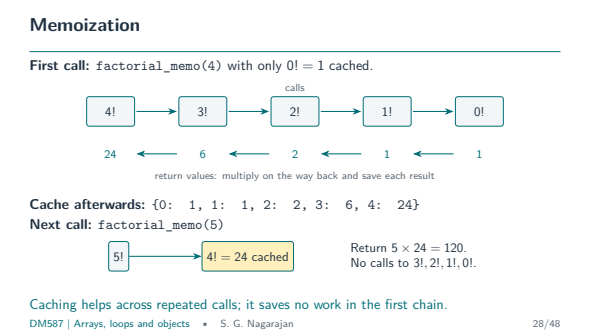


In [22]:
cache = {0: 1}

def factorial_memo(n):
    print("Called with:", n)
    if n not in cache:
        cache[n] = n * factorial_memo(n - 1)
    else:
        print("Using cached result for:", n)
    return cache[n]

print("First calculation:")
print("4! =", factorial_memo(4))
print("Cache:", sorted(cache.items()))
print("Next calculation:")
print("5! =", factorial_memo(5))


First calculation:
Called with: 4
Called with: 3
Called with: 2
Called with: 1
Called with: 0
Using cached result for: 0
4! = 24
Cache: [(0, 1), (1, 1), (2, 2), (3, 6), (4, 24)]
Next calculation:
Called with: 5
Called with: 4
Using cached result for: 4
5! = 120


The first calculation prints calls with 4, 3, 2, 1, 0 and produces 24. The next prints only calls with 5 and 4 and produces 120, using the cached result for 4. Calling factorial_memo(4) again returns 24 immediately. For a single factorial, a loop is usually simpler and faster than either recursive version. The diagnostic print calls above show the chain; remove them before measuring speed.


## 4. Objects and classes
### A backpack
A backpack has state (owner, capacity and contents) and actions (put, take and empty). Each backpack keeps its own state, while the same rules apply to every backpack. A dictionary can store state; a class groups state with related operations. First discuss this in words. Python syntax comes later.

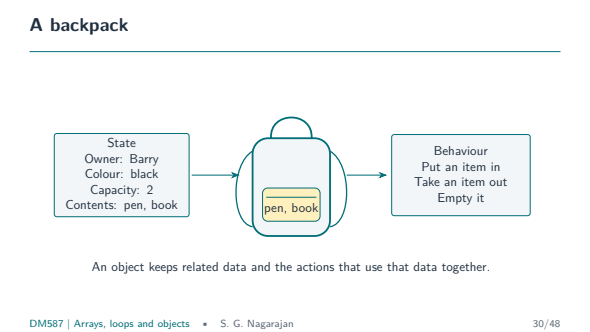


### Design exploration: bank accounts
Alice and Bob each have an account. Design a class and give these two instances different starting values. What state should each account store? Which methods act on one account, and which involve another? What rules should the operations check or preserve? Suggest specialised account types and identify what they inherit, add or change. Sketch before opening the possibilities below; there is no single required design.

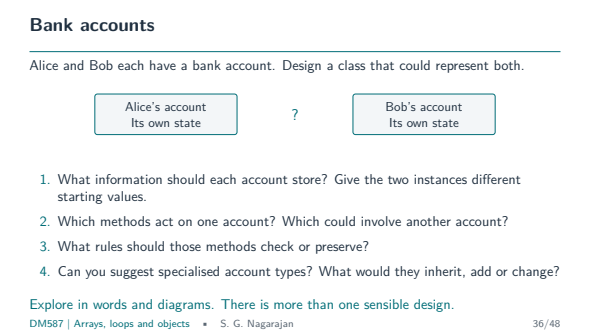


### Possible choices
**One account:** deposit, withdraw, show balance, list transactions.

**Interactions:** transfer money, compare balances, calculate a combined balance.

**Rules:** positive amounts, sufficient funds, conservation of the combined balance in a transfer, active accounts. These assume the simple no-fee transfer model.

**Possible subclasses:** SavingsAccount adds interest; CurrentAccount adds an overdraft facility; StudentAccount waives selected fees; BusinessAccount applies transaction fees. These are possible design choices, not universal banking rules or a requirement to create every subclass.

State might include owner, account number and balance, plus history or status if the selected methods need them. The operations you choose determine the data you need.

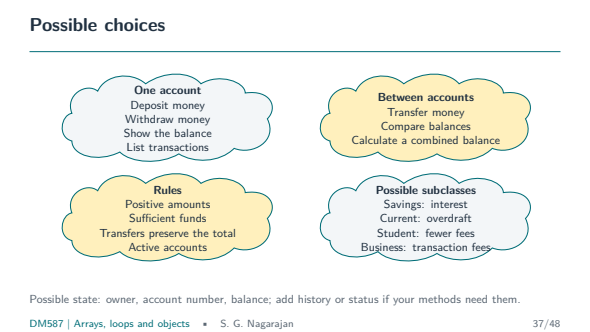


In [23]:
class Backpack:
    """A backpack with an owner, colour, capacity and its own contents."""
    def __init__(self, name, color, max_size=2):
        self.name = name
        self.color = color
        self.max_size = max_size
        self.contents = []

    def put(self, item):
        """Add an item if there is space."""
        if len(self.contents) < self.max_size:
            self.contents.append(item)
        else:
            print("No Room!")

    def take(self, item):
        """Remove an item already in the backpack."""
        self.contents.remove(item)

    def dump(self):
        """Replace the contents with an empty list."""
        self.contents = []

    def transfer(self, other, item):
        """Transfer an item only when both backpacks allow it."""
        if other is self:
            print("Choose a different backpack.")
            return False
        if item not in self.contents:
            print("Item not found.")
            return False
        if len(other.contents) >= other.max_size:
            print("No room in the other backpack.")
            return False
        self.contents.remove(item)
        other.contents.append(item)
        return True

    def combined_item_count(self, others):
        """Count items in this backpack and a list of other backpacks."""
        total = len(self.contents)
        for backpack in others:
            total += len(backpack.contents)
        return total


### Independent instances
Predict both contents lists after the method call. Then add a different item to the other backpack. `Backpack(...)` creates an instance; `pack.put(...)` calls a method on that instance.


In [24]:
pack = Backpack("Barry", "black")
other = Backpack("Ada", "blue")
pack.put("book")
print("Barry:", pack.contents, "expected:", ["book"])
print("Ada:", other.contents, "expected:", [])


Barry: ['book'] expected: ['book']
Ada: [] expected: []


### Aliases and rules
Assignment makes another name for the same object. It does not call the constructor. Capacity checking belongs in the method so callers do not have to duplicate the rule.

**Change it:** give a new backpack capacity 3 and repeat the insertions. Re-run the instance-creation cell to reset these objects.


In [25]:
alias = pack
alias.put("pen")
pack.put("coat")
print("Same object:", alias is pack)
print("Barry:", pack.contents, "expected:", ["book", "pen"])
print("Ada:", other.contents, "expected:", [])
pack.dump()
print("After dump:", pack.contents, "expected:", [])


No Room!
Same object: True
Barry: ['book', 'pen'] expected: ['book', 'pen']
Ada: [] expected: []
After dump: [] expected: []


### An operation on two objects
The transfer method belongs to the source Backpack. The argument other is the destination Backpack. The method checks the item and capacity before changing either contents list. The examples below include a successful transfer, a full destination and a missing item.

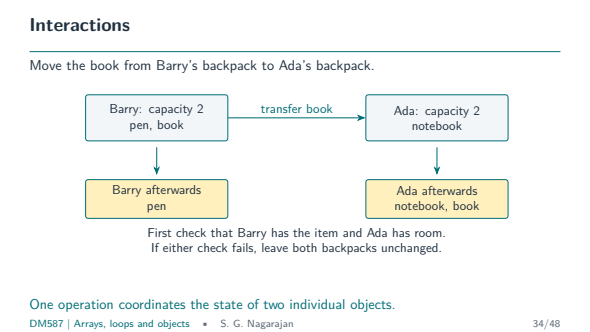


In [26]:
source_pack = Backpack("Barry", "black")
target_pack = Backpack("Ada", "blue")
source_pack.put("book")
source_pack.put("pen")
target_pack.put("map")
print("Transfer book:", source_pack.transfer(target_pack, "book"))
print("Source:", source_pack.contents, "expected:", ["pen"])
print("Destination:", target_pack.contents, "expected:", ["map", "book"])
print("Try transferring pen to the full destination:")
print("Successful:", source_pack.transfer(target_pack, "pen"))
print("Source unchanged:", source_pack.contents)
print("Destination unchanged:", target_pack.contents)
print("Try an item the source does not have:")
print("Successful:", source_pack.transfer(target_pack, "coat"))


Transfer book: True
Source: ['pen'] expected: ['pen']
Destination: ['map', 'book'] expected: ['map', 'book']
Try transferring pen to the full destination:
No room in the other backpack.
Successful: False
Source unchanged: ['pen']
Destination unchanged: ['map', 'book']
Try an item the source does not have:
Item not found.
Successful: False


### A method accepting a list of objects
A parameter may hold a list instead of a single object. combined_item_count loops over others. Use distinct backpacks in the list and do not include self, so each item is counted once. In contrast, __add__ below expects one ComplexNumber as other. The parameter names do not impose a type.


In [27]:
extra_pack = Backpack("Emmy", "red")
backpacks = [target_pack, extra_pack]
print("Combined item count:", source_pack.combined_item_count(backpacks), "expected:", 3)
print("The source still contains:", source_pack.contents)


Combined item count: 3 expected: 3
The source still contains: ['pen']


### A mathematical object
A complex number has two pieces of state. Conjugation and addition return new ComplexNumber instances. Magnitude returns an ordinary number.

`__add__` supplies the behaviour for `+`; `__abs__` supplies the behaviour for `abs`. `__str__` returns text used by print. The `.format` placeholders `{0}` and `{1}` insert the first and second values supplied; the stored number is unchanged.

Python already provides a built-in complex type. We write this small class to understand the design, rather than to replace that built-in type in ordinary numerical work.

In __add__, other is one ComplexNumber, not a list. Method arguments can also be lists of objects; a method written for a list would loop over its elements rather than use other.real directly. The parameter name other has no special Python meaning.

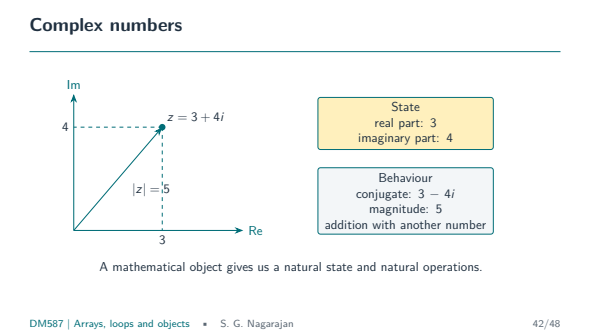


In [28]:
class ComplexNumber:
    """A simple complex number used to illustrate class design."""
    def __init__(self, real, imag=0):
        self.real = real
        self.imag = imag

    def conjugate(self):
        return ComplexNumber(self.real, -self.imag)

    def __add__(self, other):
        return ComplexNumber(self.real + other.real,
                             self.imag + other.imag)

    def __abs__(self):
        return (self.real ** 2 + self.imag ** 2) ** 0.5

    def __str__(self):
        sign = "+" if self.imag >= 0 else "-"
        return "({0}{1}{2}j)".format(self.real, sign, abs(self.imag))

z = ComplexNumber(3, 4)
w = ComplexNumber(1, -2)
print("z:", z)
print("Conjugate:", z.conjugate(), "expected: (3-4j)")
print("Magnitude:", abs(z), "expected:", 5.0)
print("Sum:", z + w, "expected: (4+2j)")
print("Original z is unchanged:", z)


z: (3+4j)
Conjugate: (3-4j) expected: (3-4j)
Magnitude: 5.0 expected: 5.0
Sum: (4+2j) expected: (4+2j)
Original z is unchanged: (3+4j)


### Composition: a graph contains connections
This optional example stores an undirected graph as a dictionary of neighbour sets. The class gathers the representation and the operations together. The caller uses add_edge and neighbours without repeating the dictionary-update logic.

**Change it:** add another edge and inspect both affected neighbour sets. add_edge handles both directions of the connection.


In [29]:
class Graph:
    """A small undirected graph, stored as neighbour sets."""
    def __init__(self):
        self.adjacency = {}

    def add_edge(self, u, v):
        if u not in self.adjacency:
            self.adjacency[u] = set()
        if v not in self.adjacency:
            self.adjacency[v] = set()
        self.adjacency[u].add(v)
        self.adjacency[v].add(u)

    def neighbours(self, u):
        return self.adjacency.get(u, set()).copy()

graph = Graph()
graph.add_edge("A", "B")
graph.add_edge("A", "C")
print("Neighbours of A:", sorted(graph.neighbours("A")))
print("Neighbours of B:", sorted(graph.neighbours("B")))


Neighbours of A: ['B', 'C']
Neighbours of B: ['A']


### Optional: inheritance
Jetpack inherits put unchanged: Backpack.put runs, including its capacity check. It overrides dump: Backpack.dump only empties contents, while Jetpack.dump empties contents and clears fuel. In the code, super().dump() reuses the parent operation before self.fuel = 0. The constructor also uses super() to initialise the inherited state, then adds fuel. fly is a new method. Fuel quantities are assumed non-negative.


In [30]:
class Jetpack(Backpack):
    """A backpack that can also use fuel for flying."""
    def __init__(self, name, color, max_size=2, fuel=10):
        super().__init__(name, color, max_size)
        self.fuel = fuel

    def fly(self, amount):
        if amount > self.fuel:
            print("Not enough fuel!")
        else:
            self.fuel -= amount

    def dump(self):
        super().dump()
        self.fuel = 0

jet = Jetpack("Barry", "silver")
jet.put("map")
jet.put("compass")
jet.put("coat")
print("Inherited capacity check:", jet.contents, "expected:", ["map", "compass"])
jet.fly(3)
print("Remaining fuel:", jet.fuel, "expected:", 7)
jet.fly(8)
print("After unsuccessful flight:", jet.fuel, "expected:", 7)
print("Before the overridden dump:", jet.contents, jet.fuel)
jet.dump()
print("After dump:", jet.contents, jet.fuel, "expected: [] 0")


No Room!
Inherited capacity check: ['map', 'compass'] expected: ['map', 'compass']
Remaining fuel: 7 expected: 7
Not enough fuel!
After unsuccessful flight: 7 expected: 7
Before the overridden dump: ['map', 'compass'] 7
After dump: [] 0 expected: [] 0


## Further exploration
- Change a constructor default and create two fresh objects.
- Add a method that reports the number of items in a Backpack.
- Use comprehensions to collect the neighbours of each graph vertex.
- Explain which objects change after a method call and which operations return a new object.

Main readings: [ACME Lab 1](https://labs.acme.byu.edu/PythonEssentials/PythonIntro/PythonIntro.html), [Lab 3](https://labs.acme.byu.edu/PythonEssentials/ObjectOriented/ObjectOriented.html), [Lab 4](https://labs.acme.byu.edu/PythonEssentials/NumpyIntro/NumpyIntro.html).

Examples draw on ACME Labs / Python Essentials, with additional DM587 examples. Attribution: Dr. J. Humpherys, [Foundations of Applied Mathematics Labs](https://github.com/Foundations-of-Applied-Mathematics/Labs), [CC BY 3.0 US](https://creativecommons.org/licenses/by/3.0/us/).
